In [28]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('/content/lung_cancer_examples.csv')
df

,Name,Surname,Age,Smokes,AreaQ,Alcohol,Result
0,John,Wick,35,3,5,4,1
1,Emma,Stone,28,0,3,1,0
2,Rahul,Sharma,45,15,7,6,1
3,Anu,Nair,22,0,2,0,0
4,David,Miller,50,20,8,7,1
5,Sophia,Lee,31,2,4,2,0
6,Arjun,Das,60,25,9,8,1
7,Maria,Jose,27,1,3,1,0
8,Kevin,Paul,40,10,6,5,1
9,Neha,Roy,24,0,2,0,0


In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.drop(columns=['Name','Surname'])

,Age,Smokes,AreaQ,Alcohol,Result
0,35,3,5,4,1
1,28,0,3,1,0
2,45,15,7,6,1
3,22,0,2,0,0
4,50,20,8,7,1
5,31,2,4,2,0
6,60,25,9,8,1
7,27,1,3,1,0
8,40,10,6,5,1
9,24,0,2,0,0


In [31]:
df.isna().sum()

,0
Name,0
Surname,0
Age,0
Smokes,0
AreaQ,0
Alcohol,0
Result,0


In [32]:
df.shape

(20, 7)

In [33]:
df.size

140

In [34]:
y=df['Result']
y

,Result
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1
9,0


In [35]:
df.describe()

,Age,Smokes,AreaQ,Alcohol,Result
count,20.000000,20.000000,20.000000,20.000000,20.000000
mean,38.950000,9.650000,5.300000,3.950000,0.500000
std,13.975448,10.418986,2.792848,3.086047,0.512989
min,21.000000,0.000000,1.000000,0.000000,0.000000
25%,27.750000,0.750000,3.000000,1.000000,0.000000
50%,34.000000,3.500000,5.000000,3.500000,0.500000
75%,50.500000,18.500000,8.000000,7.000000,1.000000
max,65.000000,30.000000,10.000000,9.000000,1.000000


In [36]:
df['Result'].value_counts()

,count
Result,
1,10
0,10


<Axes: >

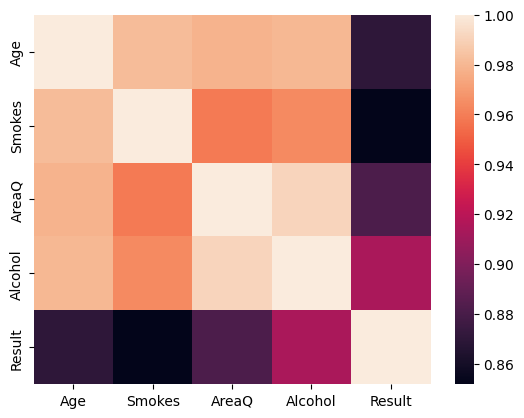

In [37]:
c=df.corr(numeric_only=True)
sns.heatmap(c)

In [38]:
x=df.drop(columns=['Result', 'Name', 'Surname'])
x

,Age,Smokes,AreaQ,Alcohol
0,35,3,5,4
1,28,0,3,1
2,45,15,7,6
3,22,0,2,0
4,50,20,8,7
5,31,2,4,2
6,60,25,9,8
7,27,1,3,1
8,40,10,6,5
9,24,0,2,0


In [39]:
df=df.drop(columns='Name')

In [40]:
df=df.drop(columns='Surname')

In [41]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [42]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [43]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [44]:
y_pred=knn.predict(x_test)
y_pred

array([0, 0, 0, 0])

In [45]:
y_test.values

array([1, 0, 0, 0])

In [46]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm



array([[3, 0],
       [1, 0]])

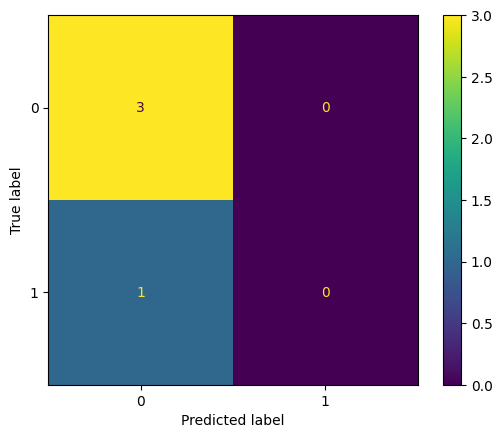

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay
cmd=ConfusionMatrixDisplay(cm)

cmd.plot()

In [48]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred)
score

0.75

In [49]:
!pip list

Package                               Version
------------------------------------- -------------------
absl-py                               2.0.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.5
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
anyio                                 4.15.1
anywidget                             0.9.21
apsw                                  3.54.0.0
argon2-cffi                           25.1

In [55]:
import pickle
pickle.dump(knn,open('knn_lung.sav','wb'))
# print(knn.predict(scaler.transform([[22,0,2,0]])))
pickle.dump(scaler,open('scaler_lungknn.sav','wb'))